# Taller integrador: de sensores IoT al dashboard

**Fundamentos de Arquitectura Cloud y Contenedores**

**Caso:** operación minera *Andes Mining*. Monitorearemos **48 equipos industriales**, durante **30 días**, con **180 000 lecturas IoT base**. Los datos son **100 % sintéticos**. El pipeline incluye fuentes → ingesta → landing → Bronze → Silver → Gold → reportes; además, calidad, observabilidad y una simulación FinOps.

**Modalidad:** ejecutable localmente sin cuenta cloud. La nube se explica como la **alternativa de implementación real**, no como un servicio que este notebook aprovisione. No se ejecutan servicios de AWS/Azure/GCP ni se incurre en cargos.

> **Pregunta guía:** ¿Cómo convertimos telemetría industrial imperfecta en indicadores confiables y económicos que puedan escalar de miles a millones de registros diarios?

**Objetivos:** diseñar un pipeline reproducible, justificar decisiones de arquitectura cloud, aplicar controles de datos, medir resultados operativos y estimar costos por unidad de dato.

## 0. Ruta de aprendizaje y arquitectura

```text
FUENTES (sensores + catálogo + mantenimientos)
      │  30 archivos CSV comprimidos y tablas maestras
      ▼
INGESTA   → verificación de lote, hash, fecha de recepción
      ▼
LANDING   → copia inmutable de los archivos originales
      ▼
BRONZE    → consolidación sin descartar errores
      ▼
SILVER    → tipado, deduplicación, calidad, enriquecimiento
      ▼
GOLD      → KPIs por día / zona / equipo + alertas
      ▼
VISUALIZACIÓN → paneles de tendencias y riesgo
      ├─ OBSERVABILIDAD → métricas del pipeline, rechazo y latencia
      └─ FINOPS → volumen, costos simulados, escenarios de optimización
```

**Decisiones del curso:** (I) Docker/Kubernetes para reproducir/escalar jobs; (II) IaaS, PaaS o serverless + métricas/logs + IaC; (III) capas Medallion, resiliencia y costo por TB/por lote.

In [15]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
import hashlib, json, shutil, sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path.cwd()
SRC = BASE / "datos_fuente"
LAKE = BASE / "data_lake"
LANDING = LAKE / "landing"
BRONZE = LAKE / "bronze"
SILVER = LAKE / "silver"
GOLD = LAKE / "gold"
REPORTS = BASE / "reportes"
for p in [SRC, LANDING, BRONZE, SILVER, GOLD, REPORTS]: p.mkdir(parents=True, exist_ok=True)

print("Ruta de trabajo:", BASE.resolve())
print("Versiones:", "pandas", pd.__version__, "numpy", np.__version__)

Ruta de trabajo: D:\Clases\UC\FundamentosNube\Taller1
Versiones: pandas 3.0.3 numpy 2.4.6


## 1. Fuentes: Más de 100 000 eventos

Cada equipo informa **temperatura (°C)**, **vibración (mm/s)** y **potencia (kW)**. En este taller se usarás datos sínteticos. Se inyectan intencionalmente anomalías físicas, lecturas faltantes, timestamps tardíos y duplicados para que la limpieza tenga valor real.

**Fuentes adicionales:** `catalogo_equipos.csv` (umbrales y zonas) y `mantenimientos.csv` (paradas programadas)

**Discusión:** en producción, los sensores podrían publicar eventos a un broker (Event Hubs/Kinesis/Pub/Sub); el dataset diario representa una **microingesta batch**, no streaming real.

In [16]:
catalogo = pd.read_csv(SRC / "catalogo_equipos.csv")
mantenimiento = pd.read_csv(SRC / "mantenimientos.csv")
# Mostar las primeras 5 filas del catálogo de equipos
display(catalogo.head(5))

,equipo_id,tipo_equipo,zona,temperatura_limite_c,vibracion_limite_mms,criticidad
0,EQ-001,Bomba,Planta Norte,78,5.25,Media
1,EQ-002,Bomba,Planta Sur,78,5.25,Media
2,EQ-003,Bomba,Mina Este,78,5.25,Media
3,EQ-004,Bomba,Mina Oeste,78,5.25,Media
4,EQ-005,Bomba,Servicios,78,5.25,Media


### Conversación de arquitectura: fuentes e ingesta

- **Batch:** simplicidad, replay de archivos y menor complejidad; latencia ligada al intervalo de extracción.
- **Streaming:** menor latencia potencial, pero requiere controlar eventos fuera de orden, reintentos y garantías de entrega.
- **Escalamiento:** particiones por fecha/equipo y procesamiento paralelo; no conviene crear miles de archivos diminutos.
- **Seguridad:** cifrado en tránsito/reposo, roles por zona, políticas de retención y secretos fuera del notebook.

## 2. Ingesta → Landing: conservar evidencia y trazabilidad

Se implementa **ingesta idempotente de archivos**: cada objeto se copia si no existe; para un nombre ya presente se verifica que el hash coincida y se rechaza una modificación silenciosa. La bitácora (`manifest_ingesta.csv`) registra archivo, tamaño, checksum SHA-256 y tiempo de proceso. Una capa cloud usaría object storage con versionado y políticas IAM.

In [17]:
T0 = perf_counter()
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda: f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()

manifest=[]
for archivo in sorted(SRC.glob('iot_*.csv.gz')):
    destino=LANDING/archivo.name
    origen_hash=sha256(archivo)
    if destino.exists() and sha256(destino)!=origen_hash:
        raise RuntimeError(f"Landing no coincide con fuente: {archivo.name}")
    if not destino.exists(): shutil.copy2(archivo,destino)
    manifest.append({"archivo":archivo.name,"bytes":destino.stat().st_size,"sha256":origen_hash,
                     "fecha_ingesta_lote_utc":datetime.now(timezone.utc).isoformat(),"estado":"OK"})
manifest_df=pd.DataFrame(manifest)
manifest_df.to_csv(LANDING/'manifest_ingesta.csv',index=False)
segundos_ingesta=perf_counter()-T0
print("Lotes verificados:",len(manifest_df),"| MB:",round(manifest_df['bytes'].sum()/1e6,2),"| seg:",round(segundos_ingesta,2))
display(manifest_df.head(3))

Lotes verificados: 30 | MB: 4.1 | seg: 0.08


,archivo,bytes,sha256,fecha_ingesta_lote_utc,estado
0,iot_2026-10-01.csv.gz,136483,81916b528d05570979e1126c1a8cd684b54cdd890317c3...,2026-11-10T01:32:26.494735+00:00,OK
1,iot_2026-10-02.csv.gz,136762,e94acd51b309523040f0e86c66a2e52ba608543838efa7...,2026-11-10T01:32:26.496744+00:00,OK
2,iot_2026-10-03.csv.gz,136673,cf6e6e3bb656dfd30ee0fbbdc54b389762833684f6204d...,2026-11-10T01:32:26.497742+00:00,OK


## 3. Bronze: lectura íntegra y contratos de esquema

Bronze preserva **todas las filas, incluyendo duplicados y errores**. Se añade `archivo_fuente` para linaje, evitando perder la evidencia necesaria para auditoría o reprocesamiento. El número de filas debería superar 180 000 debido a los reenvíos simulados.

In [18]:
T0=perf_counter()
partes=[]
for archivo in sorted(LANDING.glob('iot_*.csv.gz')):
    t=pd.read_csv(archivo, low_memory=False)
    t['archivo_fuente']=archivo.name
    partes.append(t)
bronze=pd.concat(partes,ignore_index=True)
bronze.to_csv(BRONZE/'telemetria_bronze.csv.gz',index=False,compression='gzip')
segundos_bronze=perf_counter()-T0
print("Registros BRONZE:",len(bronze))
print("Columnas:", list(bronze.columns))
assert len(bronze)>100_000
assert bronze['evento_id'].duplicated().sum()>0

Registros BRONZE: 181800
Columnas: ['evento_id', 'equipo_id', 'fecha_evento', 'fecha_ingesta', 'temperatura_c', 'vibracion_mms', 'potencia_kw', 'origen', 'archivo_fuente']


In [19]:
# Mostrar las primeras 5 filas del DataFrame BRONZE
bronze.head(5)

,evento_id,equipo_id,fecha_evento,fecha_ingesta,temperatura_c,vibracion_mms,potencia_kw,origen,archivo_fuente
0,EV-000000296,EQ-003,2026-10-01T08:50:04Z,2026-10-01T12:12:28Z,63.17,3.074,77.52,iot_gateway_simulado,iot_2026-10-01.csv.gz
1,EV-000003084,EQ-025,2026-10-01T16:07:53Z,2026-10-01T17:33:30Z,41.18,3.009,37.18,iot_gateway_simulado,iot_2026-10-01.csv.gz
2,EV-000002147,EQ-018,2026-10-01T04:13:41Z,2026-10-01T04:15:21Z,82.04,4.528,173.91,iot_gateway_simulado,iot_2026-10-01.csv.gz
3,EV-000003512,EQ-029,2026-10-01T02:17:53Z,2026-10-01T02:18:14Z,76.25,3.952,36.44,iot_gateway_simulado,iot_2026-10-01.csv.gz
4,EV-000004848,EQ-039,2026-10-01T18:49:12Z,2026-10-01T18:54:26Z,80.17,4.230,155.07,iot_gateway_simulado,iot_2026-10-01.csv.gz


## 4. Silver: deduplicar, validar y enriquecer

**Reglas reproducibles:** identificador único de evento; equipo existente en catálogo; timestamp legible; temperatura entre 0 y 150 °C, vibración entre 0 y 50 mm/s, potencia mayor que 0 y menor o igual a 1000 kW; lecturas no nulas. Las filas que violen reglas se guardan en `cuarentena.csv.gz`. Se conserva **un solo evento por ID**, priorizando el timestamp de ingesta más antiguo.

La calidad no consiste en esconder filas inválidas: se debe medir **qué se excluye, por qué y cuánto afecta al negocio**.

In [20]:
T0=perf_counter()
silver=bronze.copy()
# Ajuste de fechas
silver['fecha_evento']=pd.to_datetime(silver['fecha_evento'],utc=True,errors='coerce')
silver['fecha_ingesta']=pd.to_datetime(silver['fecha_ingesta'],utc=True,errors='coerce')

# Ajuste de tipos de datos
for c in ['temperatura_c','vibracion_mms','potencia_kw']:
    silver[c]=pd.to_numeric(silver[c],errors='coerce')
silver=silver.sort_values(['fecha_ingesta','evento_id'],kind='stable')
filas_duplicadas=silver['evento_id'].duplicated(keep='first')
duplicados=silver[filas_duplicadas].copy()
silver=silver[~filas_duplicadas].copy()

# Validación de datos
silver=silver.merge(catalogo,on='equipo_id',how='left',validate='many_to_one')
mal_equipo=silver['tipo_equipo'].isna()
mal_fecha=silver['fecha_evento'].isna()|silver['fecha_ingesta'].isna()

# Validacion de rangos de valores
mal_temp=~silver['temperatura_c'].between(0,150)
mal_vib=~silver['vibracion_mms'].between(0,50)
mal_pot=~silver['potencia_kw'].between(0,1000,inclusive='right')
valida=~(mal_equipo|mal_fecha|mal_temp|mal_vib|mal_pot)
cuarentena=silver[~valida].copy()
cuarentena['motivo_rechazo']=np.select(
    [mal_equipo[~valida],mal_fecha[~valida],mal_temp[~valida],mal_vib[~valida],mal_pot[~valida]],
    ['equipo_inexistente','fecha_invalida','temperatura_invalida','vibracion_invalida','potencia_invalida'],
    default='otro')
silver=silver[valida].copy()
silver['dia']=silver['fecha_evento'].dt.strftime('%Y-%m-%d')
silver['latencia_ingesta_min']=(silver['fecha_ingesta']-silver['fecha_evento']).dt.total_seconds()/60
silver['alerta_temperatura']=silver['temperatura_c']>silver['temperatura_limite_c']
silver['alerta_vibracion']=silver['vibracion_mms']>silver['vibracion_limite_mms']
silver['alerta_critica']=silver['alerta_temperatura']|silver['alerta_vibracion']
silver['energia_kwh_estimada']=silver['potencia_kw']*(24/125)  # muestreo nominal: 125 muestras/día/equipo

# Guardar los resultados en SILVER
silver.to_csv(SILVER/'telemetria_silver.csv.gz',index=False,compression='gzip')
cuarentena.to_csv(SILVER/'cuarentena.csv.gz',index=False,compression='gzip')
duplicados.to_csv(SILVER/'duplicados.csv.gz',index=False,compression='gzip')
segundos_silver=perf_counter()-T0

# Reporte de calidad
reporte_calidad=pd.DataFrame([
    ['filas_brutas',len(bronze)], ['duplicados_rechazados',len(duplicados)],
    ['filas_invalidas',len(cuarentena)],['filas_silver',len(silver)],
    ['porcentaje_validos_de_filas_bronze',round(100*len(silver)/len(bronze),2)],
    ['alertas_criticas',int(silver['alerta_critica'].sum())],
    ['ingesta_p95_min',round(float(silver['latencia_ingesta_min'].quantile(.95)),2)]],
    columns=['metrica','valor'])
reporte_calidad.to_csv(REPORTS/'calidad_pipeline.csv',index=False)
display(reporte_calidad)
assert silver['evento_id'].is_unique
assert silver['temperatura_c'].between(0,150).all()
assert silver['equipo_id'].notna().all()

,metrica,valor
0,filas_brutas,181800.00
1,duplicados_rechazados,1800.00
2,filas_invalidas,1361.00
3,filas_silver,178639.00
4,porcentaje_validos_de_filas_bronze,98.26
5,alertas_criticas,1331.00
6,ingesta_p95_min,17.47


### Verificación avanzada: ¿qué significa exactamente Silver?

Silver es un conjunto **confiable según las reglas del caso**: no garantiza por sí solo calibración de sensores, ausencia de sesgos ni exactitud metrológica. Una empresa añadiría catálogo de esquemas, reglas versionadas, historización de metadatos, contratos de datos y pruebas de anomalías por contexto operativo.

## 5. Gold: productos de datos útiles para negocio

Publicaremos agregados por **día, zona y tipo de equipo** y una tabla de **equipos de mayor riesgo**. El KPI `energia_kwh_estimada` es una aproximación didáctica suponiendo intervalos nominales iguales, **no** lectura real de medidor energético ni estimación válida para facturación.

In [21]:
T0=perf_counter()

# Agregaciones diarias
gold_diaria=(silver.groupby(['dia','zona','tipo_equipo'],as_index=False)
  .agg(eventos=('evento_id','size'),temperatura_promedio_c=('temperatura_c','mean'),
       vibracion_p95_mms=('vibracion_mms',lambda x:x.quantile(.95)),
       potencia_promedio_kw=('potencia_kw','mean'),
       energia_kwh_estimada=('energia_kwh_estimada','sum'),
       alertas_criticas=('alerta_critica','sum'),
       p95_latencia_ingesta_min=('latencia_ingesta_min',lambda x:x.quantile(.95))))
gold_diaria['tasa_alertas_pct']=100*gold_diaria['alertas_criticas']/gold_diaria['eventos']

# Agregaciones por equipo
gold_equipos=(silver.groupby(['equipo_id','tipo_equipo','zona','criticidad'],as_index=False)
  .agg(lecturas=('evento_id','size'),alertas=('alerta_critica','sum'),
       temperatura_max_c=('temperatura_c','max'),
       vibracion_max_mms=('vibracion_mms','max'),
       energia_kwh_estimada=('energia_kwh_estimada','sum')))
gold_equipos['tasa_alertas_pct']=100*gold_equipos['alertas']/gold_equipos['lecturas']
gold_equipos=gold_equipos.sort_values(['alertas','tasa_alertas_pct'],ascending=False)

mantenimiento['fecha_mantenimiento']=pd.to_datetime(mantenimiento['fecha_mantenimiento'])
gold_diaria.to_csv(GOLD/'indicadores_diarios.csv',index=False)
gold_equipos.to_csv(GOLD/'ranking_equipos.csv',index=False)
segundos_gold=perf_counter()-T0
display(gold_diaria.head(7).round(2))
display(gold_equipos.head(8).round(2))

,dia,zona,tipo_equipo,eventos,temperatura_promedio_c,vibracion_p95_mms,potencia_promedio_kw,energia_kwh_estimada,alertas_criticas,p95_latencia_ingesta_min,tasa_alertas_pct
0,2026-09-30,Mina Este,Camion,1,81.14,3.34,143.19,27.49,0,1.08,0.0
1,2026-09-30,Mina Este,Compresor,1,69.38,3.44,111.50,21.41,0,1.37,0.0
2,2026-09-30,Mina Este,Ventilador,1,46.73,2.60,36.99,7.10,0,6.30,0.0
3,2026-09-30,Mina Oeste,Bomba,1,63.01,3.01,75.20,14.44,0,0.50,0.0
4,2026-09-30,Mina Oeste,Camion,2,81.54,4.05,155.57,59.74,0,7.74,0.0
5,2026-09-30,Mina Oeste,Faja,1,85.15,5.01,45.46,8.73,1,4.18,100.0
6,2026-09-30,Mina Oeste,Ventilador,1,44.62,2.58,37.35,7.17,0,7.60,0.0


,equipo_id,tipo_equipo,zona,criticidad,lecturas,alertas,temperatura_max_c,vibracion_max_mms,energia_kwh_estimada,tasa_alertas_pct
3,EQ-004,Bomba,Mina Oeste,Media,3717,37,103.51,12.62,53630.67,1.00
31,EQ-032,Ventilador,Planta Sur,Media,3728,37,87.92,7.78,25065.91,0.99
47,EQ-048,Compresor,Patio,Alta,3717,36,113.28,13.15,81978.42,0.97
30,EQ-031,Ventilador,Planta Norte,Media,3720,36,91.56,8.23,25029.37,0.97
11,EQ-012,Faja,Patio,Media,3724,36,92.37,9.75,30068.67,0.97
29,EQ-030,Ventilador,Patio,Media,3728,36,85.36,7.58,25060.90,0.97
27,EQ-028,Ventilador,Mina Oeste,Media,3720,35,86.42,7.89,25013.49,0.94
45,EQ-046,Compresor,Mina Oeste,Alta,3721,34,114.23,13.52,82023.01,0.91


## 6. Capa de consumo: SQL y visualizaciones

En nube, Gold podría estar en un almacén analítico o ser consultado desde archivos optimizados. Para mantener el laboratorio **sin cuentas ni cargos**, se usa SQLite como motor SQL local.

In [22]:
con=sqlite3.connect(GOLD/'datamart_iot.sqlite')
gold_diaria.to_sql('kpi_diarios',con,if_exists='replace',index=False)
gold_equipos.to_sql('ranking_equipos',con,if_exists='replace',index=False)
consulta="""
SELECT zona, SUM(eventos) AS eventos, SUM(alertas_criticas) AS alertas,
       ROUND(100.0*SUM(alertas_criticas)/SUM(eventos),2) AS tasa_alertas_pct,
       ROUND(SUM(energia_kwh_estimada),0) AS energia_estimada_kwh
FROM kpi_diarios GROUP BY zona ORDER BY tasa_alertas_pct DESC;
"""
resultado_sql=pd.read_sql_query(consulta,con)
con.close()
display(resultado_sql)

,zona,eventos,alertas,tasa_alertas_pct,energia_estimada_kwh
0,Planta Norte,29778,241,0.81,512228.0
1,Mina Oeste,29751,238,0.80,570311.0
2,Patio,29775,224,0.75,651531.0
3,Planta Sur,29773,219,0.74,511948.0
4,Servicios,29771,205,0.69,652345.0
5,Mina Este,29791,204,0.68,571269.0


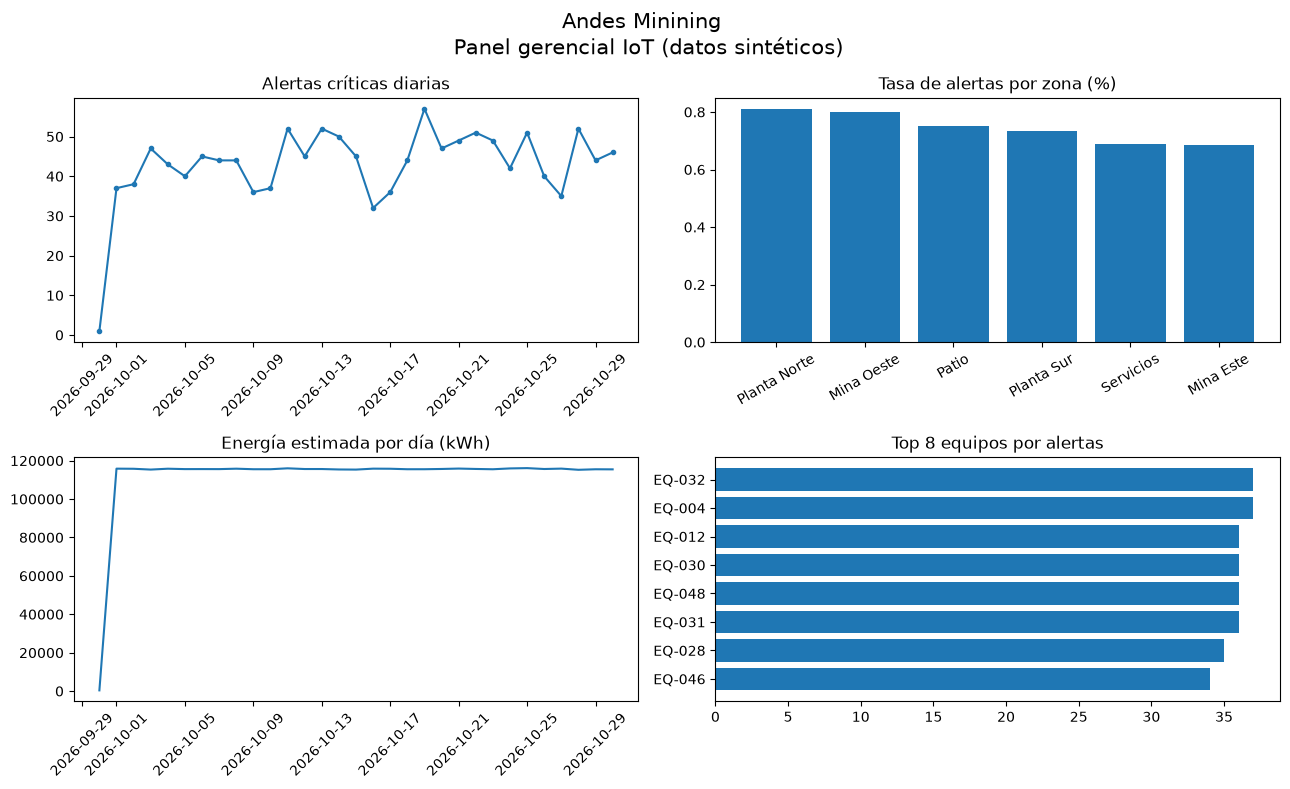

In [23]:
# Generación de gráficos
fig,axs=plt.subplots(2,2,figsize=(13,8))
serie=silver.groupby('dia',as_index=False).agg(alertas=('alerta_critica','sum'))
axs[0,0].plot(pd.to_datetime(serie['dia']),serie['alertas'],marker='o',markersize=3)
axs[0,0].set_title('Alertas críticas diarias'); axs[0,0].tick_params(axis='x',rotation=45)
r=(silver.groupby('zona')['alerta_critica'].mean()*100).sort_values(ascending=False)
axs[0,1].bar(r.index,r.values); axs[0,1].set_title('Tasa de alertas por zona (%)');axs[0,1].tick_params(axis='x',rotation=30)
serieenergia=gold_diaria.groupby('dia')['energia_kwh_estimada'].sum()
axs[1,0].plot(pd.to_datetime(serieenergia.index),serieenergia.values)
axs[1,0].set_title('Energía estimada por día (kWh)');axs[1,0].tick_params(axis='x',rotation=45)
top=gold_equipos.head(8).sort_values('alertas')
axs[1,1].barh(top['equipo_id'],top['alertas']);axs[1,1].set_title('Top 8 equipos por alertas')
fig.suptitle('Andes Minining \n Panel gerencial IoT (datos sintéticos)',fontsize=15)
fig.tight_layout()
fig.savefig(REPORTS/'dashboard_iot.png',dpi=150,bbox_inches='tight')
plt.show()

## 7. Observabilidad de pipeline: no es lo mismo que calidad de datos

**Métricas de pipeline:** tiempo por etapa, filas procesadas y rechazadas, porcentaje de éxito, latencia de eventos. **Métricas de negocio:** alertas por zona y consumo energético estimado. No confundirlas: una ingesta puede terminar en 2 s y, aun así, producir datos inválidos.

**SLO didácticos sugeridos:** `≥ 98 %` de registros válidos únicos; `p95 de latencia < 30 min`; `100 %` de archivos esperados recibidos.

In [24]:
metricas_operativas={
 "archivos_esperados":30,"archivos_recibidos":len(manifest_df),
 "seg_ingesta_landing":round(segundos_ingesta,3),"seg_bronze":round(segundos_bronze,3),
 "seg_silver":round(segundos_silver,3),"seg_gold":round(segundos_gold,3),
 "filas_bronze":len(bronze),"filas_silver":len(silver),
 "filas_cuarentena":len(cuarentena),"filas_duplicadas":len(duplicados),
 "pct_validas_unicas_sobre_bronze":round(100*len(silver)/len(bronze),2),
 "p95_latencia_min":round(float(silver['latencia_ingesta_min'].quantile(.95)),2),
 "fecha_utc_reporte":datetime.now(timezone.utc).isoformat()}
metricas_operativas['slo_archivos_100pct']=metricas_operativas['archivos_recibidos']==30

# SLO de calidad: sobre eventos distintos, no sobre reintentos duplicados
metricas_operativas['pct_validas_sobre_eventos_unicos']=round(100*len(silver)/(len(silver)+len(cuarentena)),2)
metricas_operativas['slo_calidad_98pct']=metricas_operativas['pct_validas_sobre_eventos_unicos']>=98
metricas_operativas['slo_p95_menor_30min']=metricas_operativas['p95_latencia_min']<30
(REPORTS/'metricas_pipeline.json').write_text(json.dumps(metricas_operativas,indent=2,ensure_ascii=False),encoding='utf-8')
display(pd.DataFrame([metricas_operativas]).T.rename(columns={0:'valor'}))

,valor
archivos_esperados,30
archivos_recibidos,30
seg_ingesta_landing,0.082
seg_bronze,2.628
seg_silver,5.172
seg_gold,0.663
filas_bronze,181800
filas_silver,178639
filas_cuarentena,1361
filas_duplicadas,1800


## 8. Cloud native + FinOps: tomar decisiones con números

En producción, las **fuentes y el almacenamiento** pueden crecer independientemente del cómputo; los jobs batch pueden ejecutarse sólo cuando llegan datos, y el monitoreo puede alertar por deterioro de calidad. Los siguientes precios son **supuestos**, no cotizaciones ni tarifas oficiales de ningún proveedor.

Calcularemos costos de una plataforma hipotética que procesa **1 TB/día**, reteniendo 30 días de datos: cómputo, almacenamiento y consultas. Compararemos un diseño base con otro optimizado mediante compresión, particionado y ejecución bajo demanda.

In [25]:
hipotesis={
 'tb_dia':1.0,'dias_mes':30,'usd_por_tb_ingestado':1.20,
 'usd_por_tb_transformado':3.40,'usd_por_tb_mes_almacenado':19.0,
 'retencion_tb_mes':30.0,'usd_por_tb_consultado':4.0,'tb_consultados_mes':25.0}
h=hipotesis
base={
 'ingesta':h['tb_dia']*h['dias_mes']*h['usd_por_tb_ingestado'],
 'transformacion':h['tb_dia']*h['dias_mes']*h['usd_por_tb_transformado'],
 'almacenamiento':h['retencion_tb_mes']*h['usd_por_tb_mes_almacenado'],
 'consultas':h['tb_consultados_mes']*h['usd_por_tb_consultado']}

# Supuestos de mejora: 60% almacenamiento, 35% cómputo, 55% scans de consulta.
optimizado={'ingesta':base['ingesta'],'transformacion':base['transformacion']*.65,
            'almacenamiento':base['almacenamiento']*.40,'consultas':base['consultas']*.45}
costos=pd.DataFrame({'categoria':list(base),'costo_base_usd':list(base.values()),
                    'costo_optimizado_usd':[optimizado[k] for k in base]})
costos['ahorro_usd']=costos['costo_base_usd']-costos['costo_optimizado_usd']
costo_base=sum(base.values()); costo_opt=sum(optimizado.values())

print(f'Costo base/mes (simulado): USD {costo_base:,.2f}')
print(f'Costo optimizado/mes: USD {costo_opt:,.2f}')
print(f'Ahorro simulado: {100*(1-costo_opt/costo_base):.1f}%')
print(f'Costo por TB de entrada: base USD {costo_base/(h["tb_dia"]*h["dias_mes"]):.2f}; optimizado USD {costo_opt/(h["tb_dia"]*h["dias_mes"]):.2f}')
costos.to_csv(REPORTS/'finops_escenarios.csv',index=False)
display(costos.round(2))

Costo base/mes (simulado): USD 808.00
Costo optimizado/mes: USD 375.30
Ahorro simulado: 53.6%
Costo por TB de entrada: base USD 26.93; optimizado USD 12.51


,categoria,costo_base_usd,costo_optimizado_usd,ahorro_usd
0,ingesta,36.0,36.0,0.0
1,transformacion,102.0,66.3,35.7
2,almacenamiento,570.0,228.0,342.0
3,consultas,100.0,45.0,55.0


### Matriz de decisión: de notebook local a Azure / AWS / Google Cloud

| Etapa | Laboratorio local | Azure (posible opción) | AWS (posible opción) | Google Cloud (posible opción) |
|---|---|---|---|---|
| Ingesta | Archivos diarios / Python | Event Hubs / Data Factory | Kinesis / Glue | Pub/Sub / Dataflow |
| Landing + Lake | Carpetas + CSV.gz | ADLS Gen2 | Amazon S3 | Cloud Storage |
| Transformación | pandas | Azure Databricks / Fabric | AWS Glue / EMR | Dataflow / Dataproc |
| SQL y consumo | SQLite + pandas | Synapse / Fabric Warehouse | Athena / Redshift | BigQuery |
| Observabilidad | JSON y KPIs | Azure Monitor | CloudWatch | Cloud Monitoring |
| Automatización | Notebook / tarea programada | Data Factory / Azure Functions | Step Functions / Lambda | Workflows / Cloud Run |

**Nota:** son alternativas conceptuales, no equivalencias exactas uno a uno ni una recomendación de contratar todos esos servicios. La selección requiere SLA, volumen, presupuesto, interoperabilidad, seguridad y competencias del equipo.

**Parquet:** en una plataforma lakehouse de producción suele preferirse un formato columnar como Parquet para Silver/Gold. Este laboratorio ejecutable se distribuye en CSV comprimido y SQLite para no obligar a instalar `pyarrow`. Quien disponga de `pyarrow` puede ejecutar el paso opcional siguiente.

In [ ]:
try:
    import pyarrow  # noqa: F401
    silver.to_parquet(SILVER/'telemetria_silver.parquet',index=False)
    gold_diaria.to_parquet(GOLD/'indicadores_diarios.parquet',index=False)
    print('Exportación opcional Parquet: OK')
except ImportError:
    print('Parquet omitido: instala pyarrow si quieres comparar formatos columnares (opcional).')

## 9. Preguntas de cierre

1. ¿Por qué conservar Landing si Bronze ya contiene todas las filas?
2. ¿Qué diferencia hay entre **exactly-once en un resultado** y reintentos de entrega?
3. ¿Cómo gestionaría eventos que llegan con 2 horas de retraso en un tablero casi en tiempo real?
4. ¿Qué indicadores se perderían si descartamos datos inválidos sin cuarentena?
5. ¿Cuándo conviene PaaS o serverless en lugar de una flota de VMs/Kubernetes?
6. ¿Qué costo adicional introduce un SLA de frescura de 1 minuto frente a uno de 24 horas?

### Referencias oficiales

- Docker overview — https://docs.docker.com/get-started/docker-overview/ ; Kubernetes documentation — https://kubernetes.io/docs/home/
- Microsoft Learn, documentación Azure — https://learn.microsoft.com/azure/ ; OpenTelemetry — https://opentelemetry.io/docs/ ; Terraform — https://developer.hashicorp.com/terraform
- Azure Architecture Center: data lakes / Medallion — https://learn.microsoft.com/en-us/azure/architecture/data-guide/scenarios/data-lake ; FinOps Foundation — https://www.finops.org/framework/ ; AWS Well-Architected — https://docs.aws.amazon.com/wellarchitected/latest/framework/welcome.html
